# 02 - Definição do target
Inadimplência = atraso >= 30 dias em alguma das 12 primeiras parcelas, em contratos aprovados e maduros. Ver `src/target.py` e `.claude/DECISIONS.md`.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200, 'display.max_columns', 50)


In [2]:
from src.data_loader import load
from src.target import construir_target
e, p = load('historico_emprestimos'), load('historico_parcelas')
obs = p.data_real_pagamento.max(); print('data de observação:', obs)
t = construir_target(e, p, obs)
print(len(t), 'de', (e.status_contrato=='aprovado').sum(), 'aprovados | taxa:', round(t.target.mean(),4))

data de observação: 2025-02-22 00:00:00


104029 de 131735 aprovados | taxa: 0.1413


In [3]:
# aprovados fora da base
ap = e[e.status_contrato=='aprovado']; sem_p = (~ap.id_contrato.isin(p.id_contrato)).sum()
print('aprovados', len(ap), '| sem linhas de parcela', sem_p, '| sem 1º vencimento (estimado pelas parcelas)', ap.data_primeiro_vencimento.isna().sum(), '| imaturos', len(ap)-sem_p-len(t))

aprovados 131735 | sem linhas de parcela 8868 | sem 1º vencimento (estimado pelas parcelas) 9023 | imaturos 18838


In [4]:
# sensibilidade à definição
r = {f'dpd>={d}': construir_target(e, p, obs, dpd=d).target.mean() for d in (30,60,90)}
r['janela 6, dpd>=30'] = construir_target(e, p, obs, janela=6).target.mean()
print(pd.Series(r).round(4))

dpd>=30              0.1413
dpd>=60              0.0824
dpd>=90              0.0446
janela 6, dpd>=30    0.0893
dtype: float64


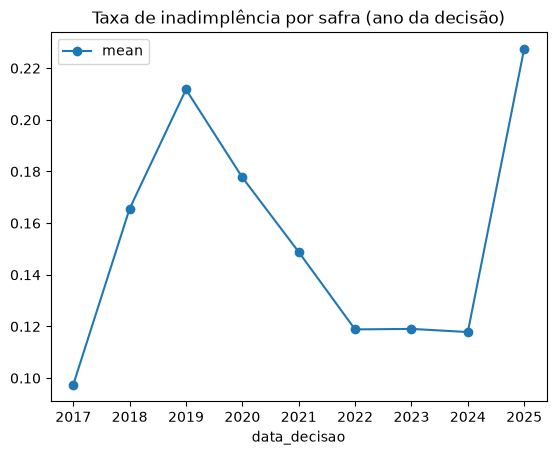

In [5]:
t.groupby(t.data_decisao.dt.year).target.agg(['size','mean']).plot(y='mean', marker='o', title='Taxa de inadimplência por safra (ano da decisão)'); plt.show()